# M2.2 — Chuva e acidentes na BR-101/SC em 2025

**Grupo R** — Flávia Schnaider; Gregori da Luz Maciel; João Victor da Silva; Pedro Henrique de Paula Cordeiro.

## 1. Objetivo e recorte

A análise investiga se existe associação entre a precipitação diária medida pelo INMET e o número de acidentes registrados pela PRF na BR-101 em Santa Catarina durante 2025. O estudo é exploratório e não permite inferir causalidade.

## 2. Importação e fontes

Os ZIPs locais são lidos diretamente. O horário PRF é interpretado em `America/Sao_Paulo`; o INMET é convertido de UTC para esse fuso antes da agregação diária. Download informado: 31/10/2026.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Markdown, display, Image

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))

from ia_chuvas_acidentes.pipeline_m22 import executar_pipeline_m22
from ia_chuvas_acidentes.eda import calcular_resumo_eda, classificar_faixa_chuva

resultado = executar_pipeline_m22(
    caminho_prf=ROOT / 'data/raw/datatran2025.zip',
    caminho_inmet=ROOT / 'data/raw/2025.zip',
    pasta_dados=ROOT / 'data/processed',
    pasta_figuras=ROOT / 'reports/figures',
    caminho_relatorio=ROOT / 'reports/resumo_m22.md',
)
resultado.metricas

{'acidentes_prf': 4222,
 'ids_duplicados': 0,
 'datas_horas_invalidas': 0,
 'coordenadas_invalidas': 0,
 'associados': 4164,
 'sem_estacao': 58,
 'estacoes_representadas': 7,
 'distancia_media_km': 17.498216187928662,
 'distancia_mediana_km': 15.601291289634094,
 'distancia_p95_km': 40.218652531810235,
 'distancia_maxima_km': 49.81298688393073,
 'estrategia_alternativa': {'cobertura_minima_pct': 90.0,
  'estacoes_elegiveis': 8,
  'associados_principal': 4164,
  'associados_alternativa': 3339,
  'estacoes_trocadas': 1599,
  'aumento_medio_distancia_km': 15.158978648431416,
  'estacoes_representadas': 3,
  'estacao_dias_validos_23h': 1087,
  'acidentes_com_chuva_valida': 3316,
  'acidentes_com_chuva_valida_principal': 2613,
  'ganho_acidentes_com_chuva_valida': 703}}

## 3. Diagnóstico de qualidade

A célula seguinte apresenta contagens observadas, duplicidades, cobertura e não correspondências. Zero de precipitação é uma medição válida; ausência permanece nula.

In [2]:
prf = pd.read_csv(resultado.tabelas['prf_tratada'])
chuva = pd.read_csv(resultado.tabelas['precipitacao_diaria'], parse_dates=['data_local'])
associacoes = pd.read_csv(resultado.tabelas['associacoes'])
nao_correspondidos = pd.read_csv(resultado.tabelas['nao_correspondidos'])
cobertura = pd.read_csv(resultado.tabelas['metricas_cobertura'])
tabela = pd.read_csv(resultado.tabelas['estacao_dia'], parse_dates=['data_local'])

diagnostico = pd.Series({
    'Acidentes PRF no recorte': len(prf),
    'IDs duplicados': int(prf['id_duplicado'].sum()),
    'Coordenadas inválidas': int((~prf['coordenadas_validas']).sum()),
    'Acidentes associados': int((associacoes['status_associacao'] == 'associado').sum()),
    'Acidentes não associados': len(nao_correspondidos),
    'Chaves estação-data repetidas': int(tabela.duplicated(['codigo_wmo', 'data_local']).sum()),
})
display(diagnostico.to_frame('Quantidade'))
display(cobertura[['codigo_wmo', 'nome_estacao', 'cobertura_anual_pct', 'estacao_dias_23h', 'acidentes_associados']])

,Quantidade
Acidentes PRF no recorte,4222
IDs duplicados,0
Coordenadas inválidas,0
Acidentes associados,4164
Acidentes não associados,58
Chaves estação-data repetidas,0


,codigo_wmo,nome_estacao,cobertura_anual_pct,estacao_dias_23h,acidentes_associados
0,A806,FLORIANOPOLIS,37.19,135,1516
1,A814,URUSSANGA,46.20,152,114
2,A815,SAO JOAQUIM,69.86,233,0
3,A816,NOVO HORIZONTE,25.21,91,0
4,A817,INDAIAL,21.22,1,0
5,A841,JOACABA,4.92,0,0
6,A845,BOM JARDIM DA SERRA - MORRO DA IGREJA,0.00,0,0
7,A848,DIONISIO CERQUEIRA,75.25,88,0
8,A851,ITAPOA,77.74,279,414
9,A857,SAO MIGUEL DO OESTE,5.19,0,0


## 4. Preparação dos dados

A precipitação é somada por estação e data local. A análise principal exige 23 de 24 horas válidas; limites de 18 e 24 horas são mantidos para sensibilidade. A soma observada de dias incompletos é preservada, mas `precipitacao_mm_dia` fica ausente.

In [3]:
sensibilidade = pd.Series({
    '18 horas': int(chuva['completo_18h'].sum()),
    '23 horas': int(chuva['completo_23h'].sum()),
    '24 horas': int(chuva['completo_24h'].sum()),
})
display(sensibilidade.to_frame('Estação-dias'))
chuva[['codigo_wmo', 'data_local', 'horas_validas', 'precipitacao_mm_observada', 'precipitacao_mm_dia', 'status_cobertura']].head()

,Estação-dias
18 horas,4600
23 horas,4361
24 horas,4169


,codigo_wmo,data_local,horas_validas,precipitacao_mm_observada,precipitacao_mm_dia,status_cobertura
0,A806,2024-12-31,3,0.0,NaN,incompleta
1,A806,2025-01-01,24,11.4,11.4,completa
2,A806,2025-01-02,24,1.0,1.0,completa
3,A806,2025-01-03,24,0.0,0.0,completa
4,A806,2025-01-04,24,0.0,0.0,completa


## 5. Integração espacial e temporal

Cada acidente é associado à estação mais próxima em até 50 km usando Haversine. A estação principal não é trocada por ausência diária. A alternativa usa apenas estações com cobertura anual de pelo menos 90% e é comparada separadamente.

In [4]:
display(associacoes['status_associacao'].value_counts().to_frame('Acidentes'))
display(pd.Series(resultado.metricas['estrategia_alternativa']).to_frame('Valor'))
assert len(associacoes) == len(prf)
assert not tabela.duplicated(['codigo_wmo', 'data_local']).any()
assert int(tabela['acidentes'].sum()) == resultado.metricas['associados']
tabela.head()

,Acidentes
status_associacao,
associado,4164
fora_limite,58


,Valor
cobertura_minima_pct,90.000000
estacoes_elegiveis,8.000000
associados_principal,4164.000000
associados_alternativa,3339.000000
estacoes_trocadas,1599.000000
aumento_medio_distancia_km,15.158979
estacoes_representadas,3.000000
estacao_dias_validos_23h,1087.000000
acidentes_com_chuva_valida,3316.000000
acidentes_com_chuva_valida_principal,2613.000000


,codigo_wmo,data_local,nome_estacao,latitude_estacao,longitude_estacao,acidentes,mortos,feridos,horas_registradas,horas_validas,...,linhas_em_timestamps_duplicados,completo_18h,completo_23h,completo_24h,precipitacao_mm_dia,criterio_min_horas,status_cobertura,mes,dia_semana,fim_semana
0,A806,2025-01-01,FLORIANOPOLIS,-27.6025,-48.62,3,0,3,24,24,...,0,True,True,True,11.4,23,completa,1,Wednesday,False
1,A806,2025-01-02,FLORIANOPOLIS,-27.6025,-48.62,3,0,3,24,24,...,0,True,True,True,1.0,23,completa,1,Thursday,False
2,A806,2025-01-03,FLORIANOPOLIS,-27.6025,-48.62,4,0,6,24,24,...,0,True,True,True,0.0,23,completa,1,Friday,False
3,A806,2025-01-04,FLORIANOPOLIS,-27.6025,-48.62,2,0,3,24,24,...,0,True,True,True,0.0,23,completa,1,Saturday,True
4,A806,2025-01-05,FLORIANOPOLIS,-27.6025,-48.62,4,0,5,24,24,...,0,True,True,True,0.4,23,completa,1,Sunday,True


## 6. Análise exploratória

As três perguntas usam somente estação-dias com precipitação completa pelo critério principal. As faixas são operacionais do projeto: 0 mm; >0 e <10 mm; 10 a <30 mm; e >=30 mm.

In [5]:
resumo = calcular_resumo_eda(tabela)
validos = tabela[tabela['precipitacao_mm_dia'].notna()].copy()
validos['faixa_chuva'] = classificar_faixa_chuva(validos['precipitacao_mm_dia'])

display(Markdown(
    f"**Pergunta A.** n={resumo['spearman_n']} estação-dias; "
    f"Spearman rho={resumo['spearman_rho']:.3f}, p={resumo['spearman_p_valor']:.3f}. "
    "A estimativa descreve associação, não causalidade."
))
display(pd.DataFrame(resumo['faixas']).T)
display(pd.DataFrame(resumo['variacao_mensal']).T.rename_axis('mes'))
display(pd.DataFrame(resumo['variacao_fim_semana']).T)
display(pd.DataFrame(resumo['variacao_estacao']).T.sort_values('media_acidentes', ascending=False))

**Pergunta A.** n=1653 estação-dias; Spearman rho=-0.042, p=0.088. A estimativa descreve associação, não causalidade.

,estacao_dias,acidentes,media_acidentes
Sem chuva (0 mm),731.0,1226.0,1.677155
Chuva leve (>0 e <10 mm),700.0,1073.0,1.532857
Chuva moderada (10 a <30 mm),164.0,240.0,1.463415
Chuva intensa (>=30 mm),58.0,74.0,1.275862


,estacao_dias,acidentes,media_acidentes
mes,,,
1,149.0,260.0,1.744966
2,131.0,223.0,1.702290
3,144.0,267.0,1.854167
4,163.0,319.0,1.957055
5,149.0,244.0,1.637584
6,138.0,164.0,1.188406
7,138.0,183.0,1.326087
8,137.0,189.0,1.379562
9,136.0,200.0,1.470588


,estacao_dias,acidentes,media_acidentes
dias_uteis,1180.0,1811.0,1.534746
fim_de_semana,473.0,802.0,1.695560


,estacao_dias,acidentes,media_acidentes
ITAJAI,363.0,1451.0,3.997245
FLORIANOPOLIS,135.0,525.0,3.888889
ITAPOA,279.0,315.0,1.129032
ARARANGUA,361.0,275.0,0.761773
URUSSANGA,152.0,46.0,0.302632
RANCHO QUEIMADO,363.0,1.0,0.002755


### 01 Distribuicao Precipitacao

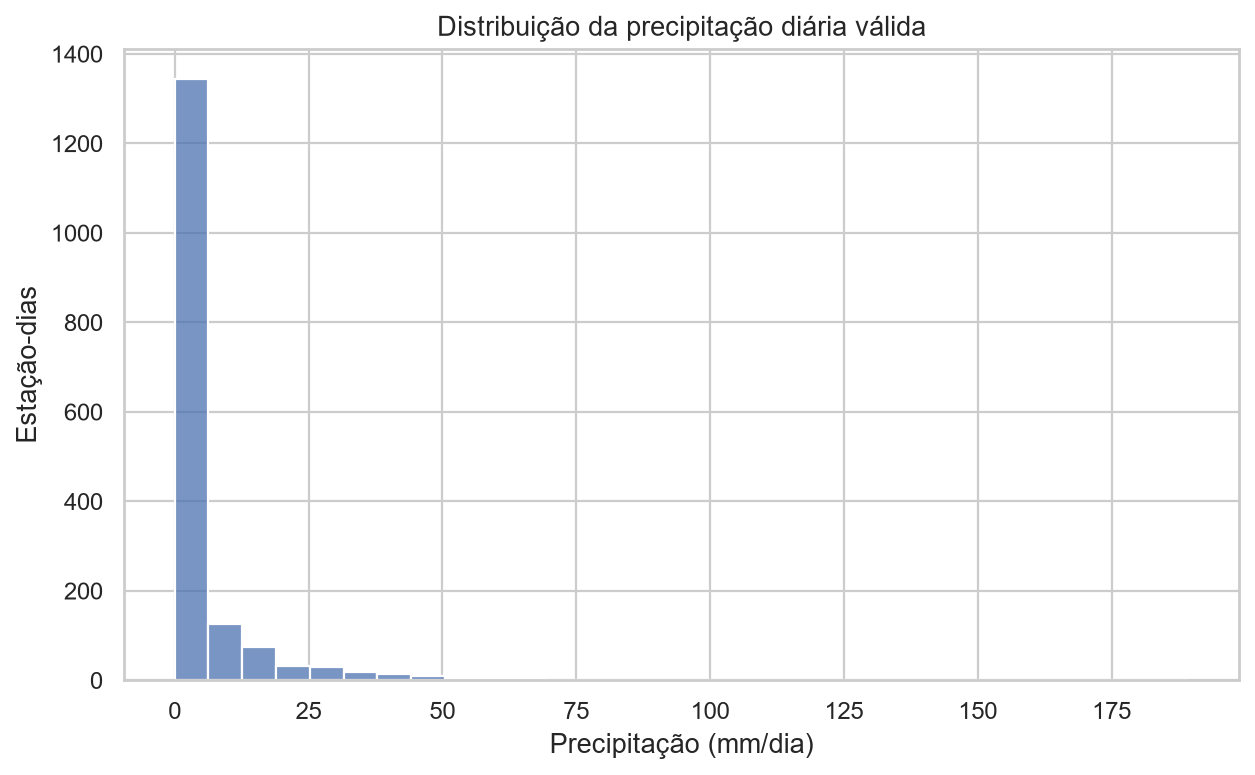

### 02 Distribuicao Acidentes

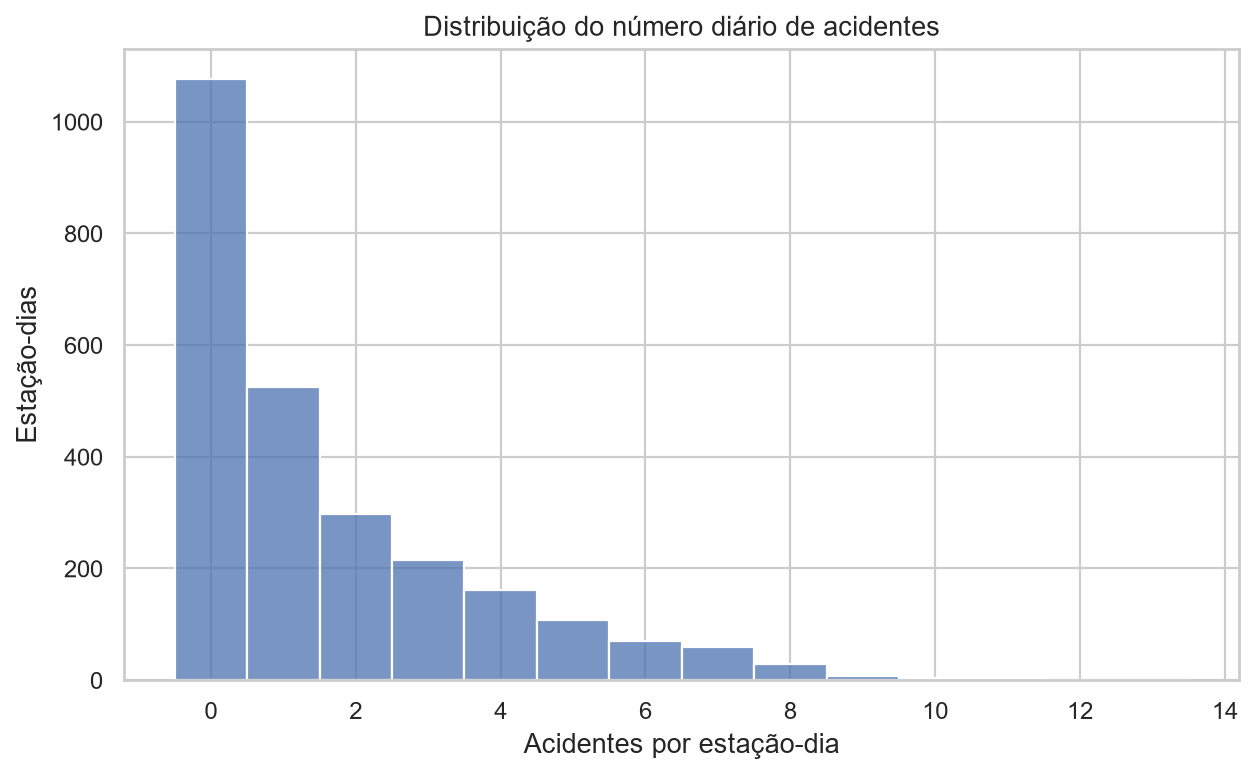

### 03 Series Temporais

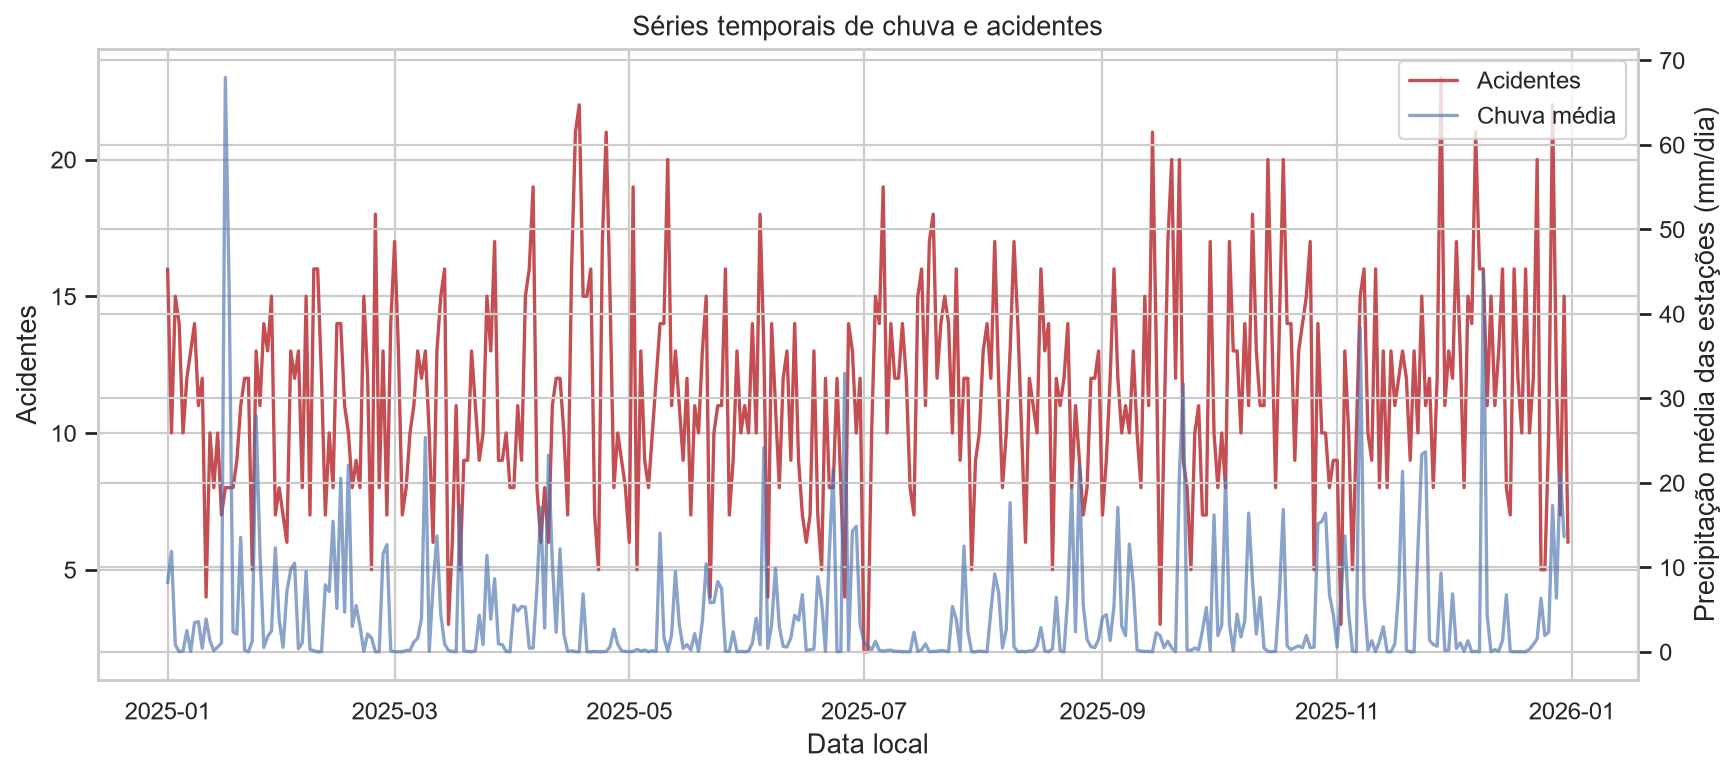

### 04 Dispersao Chuva Acidentes

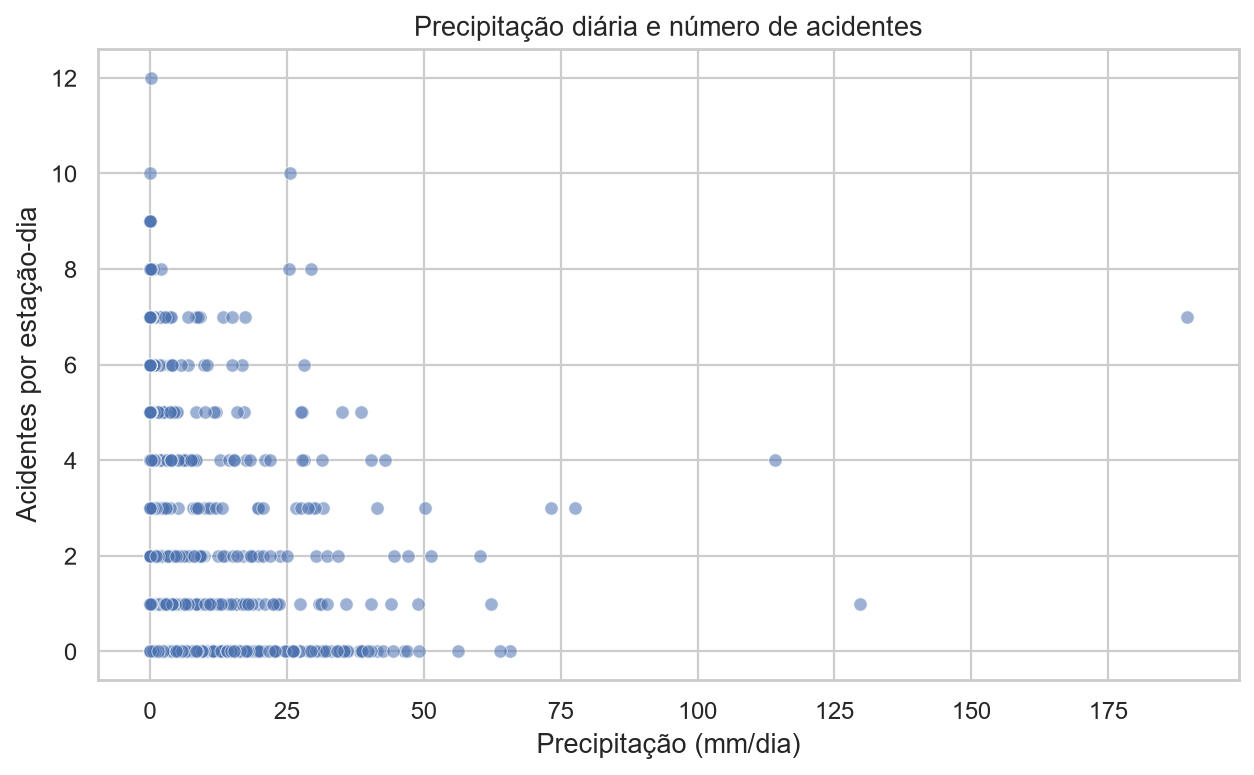

### 05 Media Acidentes Faixa Chuva

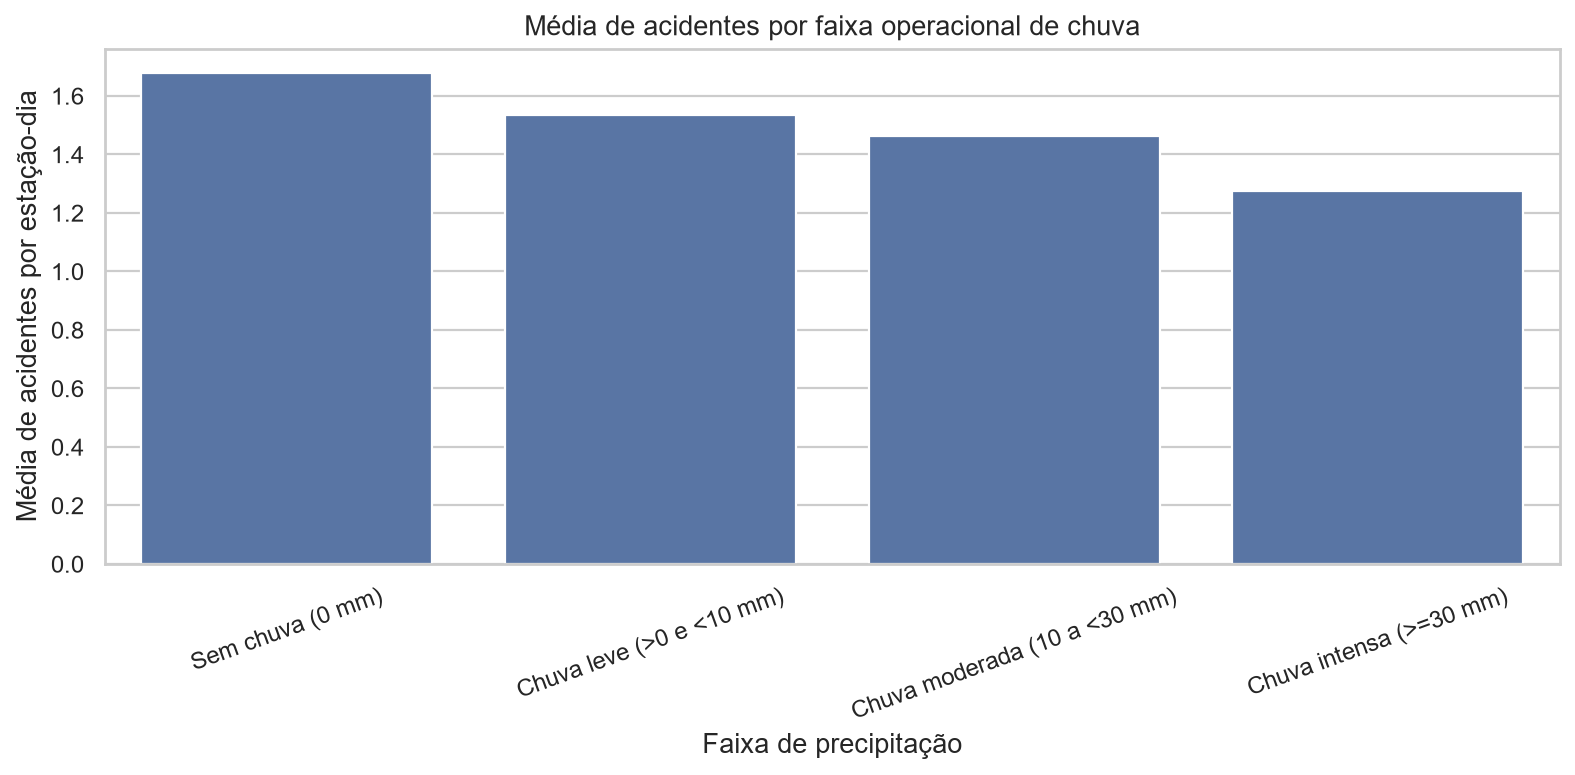

### 06 Media Acidentes Mes

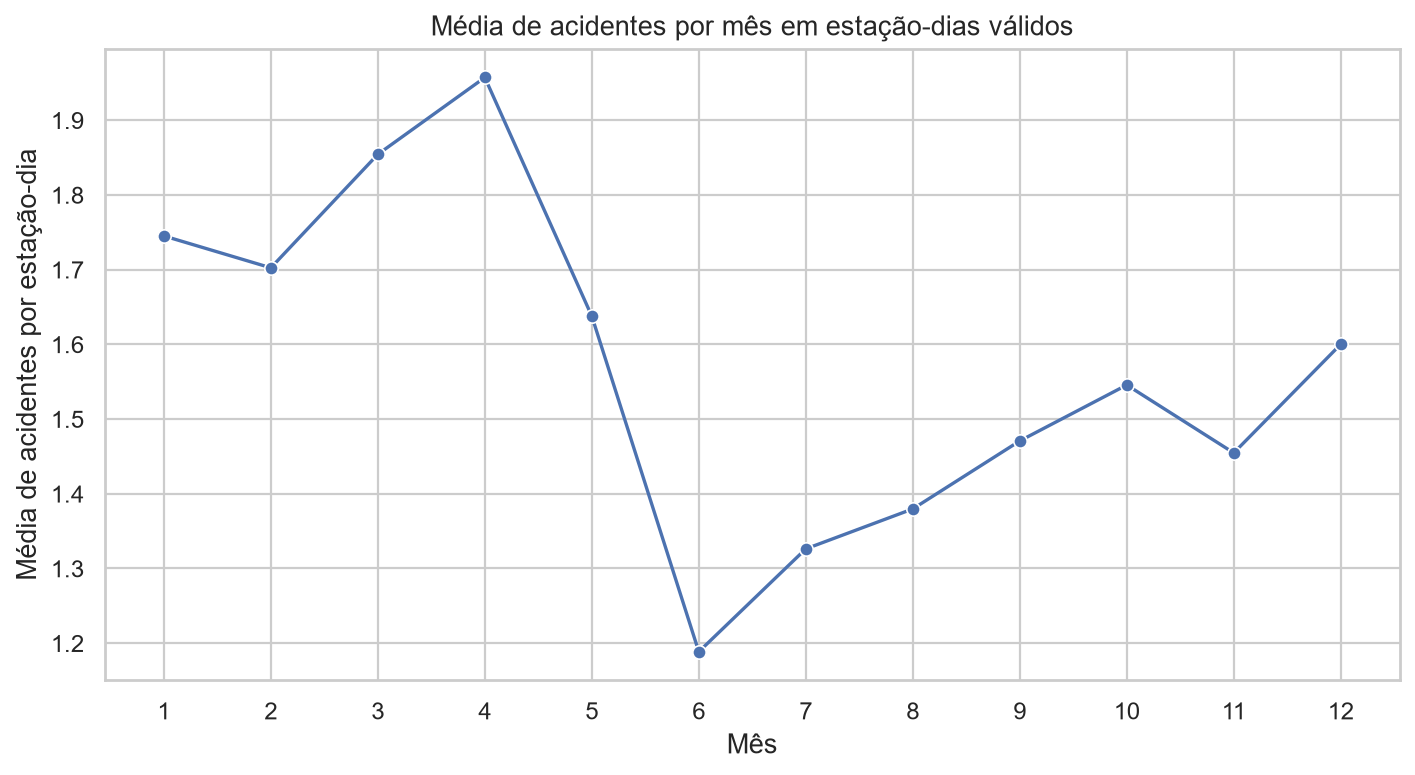

### 07 Cobertura Estacoes

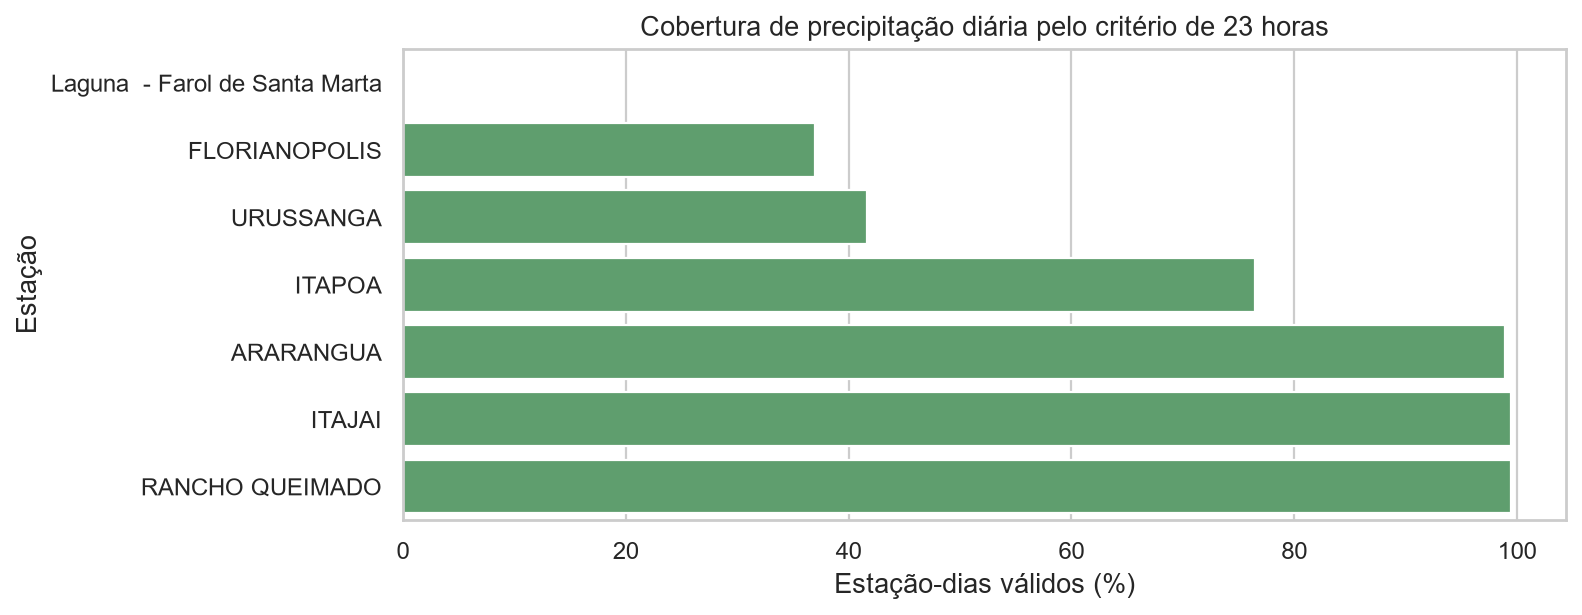

### 08 Media Acidentes Estacao

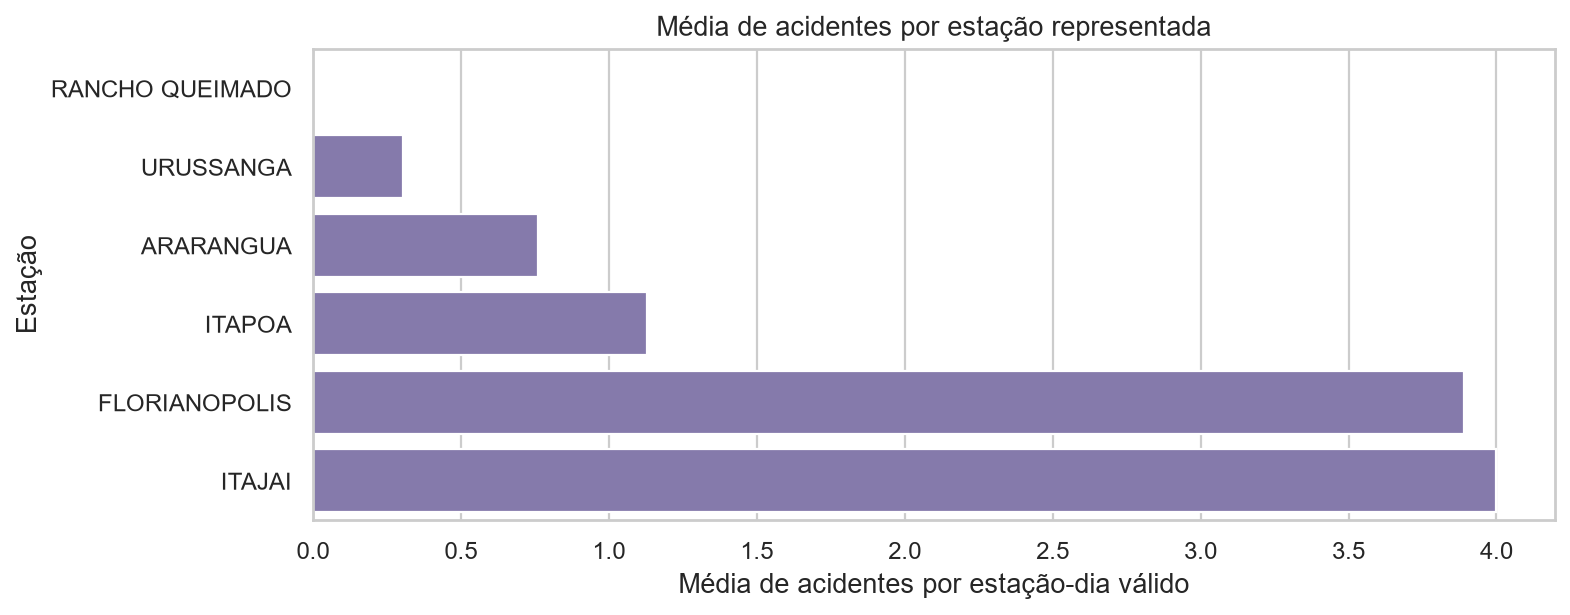

In [6]:
for caminho in resultado.figuras:
    display(Markdown('### ' + caminho.stem.replace('_', ' ').title()))
    display(Image(filename=str(caminho)))

## 7. Limitações e conclusões

A análise é limitada pela cobertura desigual das estações, distância entre estação e acidente, relevo e microclimas, diferenças entre medição instrumental e condição declarada na ocorrência e ausência de volume de tráfego. Dias sem medição não foram classificados como secos.

Os resultados descrevem associações no recorte de 2025 e não demonstram que chuva cause ou evite acidentes. Para a M3, uma eventual modelagem deverá preservar meses finais como teste temporal e ajustar transformações somente no período de desenvolvimento.

In [7]:
display(Markdown((ROOT / 'reports/resumo_m22.md').read_text(encoding='utf-8')))

# M2.2 — Integração e análise exploratória

## Recorte e rastreabilidade

- PRF: 4222 acidentes na BR-101/SC em 2025, com horário interpretado como `America/Sao_Paulo`.
- Associação principal: 4164 acidentes associados à estação mais próxima em até 50 km; 58 não associados.
- Estações representadas: 7.
- IDs duplicados sinalizados: 0; coordenadas inválidas: 0.
- Distância média dos acidentes associados: 17,50 km.
- Download dos ZIPs informado pelo usuário: **31/10/2026**.
- Unidade analítica: estação-data local. A análise principal exige pelo menos 23 horas válidas.

## Qualidade e perdas

O calendário contém 2555 estação-dias. O denominador principal é de **1653 estação-dias** com precipitação diária válida (64,70%). Neles ocorreram 2613 dos 4164 acidentes contabilizados no calendário.

Sensibilidade do critério de completude: 18 h = 1661 dias; 23 h = 1653 dias; 24 h = 1636 dias.

A alternativa restrita a estações com cobertura anual >=90% associou 3339 acidentes, trocou a estação de 1599 ocorrências comparáveis e alterou a distância média em 15,16 km. Sua amostra utilizável contém 3316 acidentes em 1087 estação-dias válidos, uma diferença de 703 acidentes em relação à associação principal. Ela é apresentada apenas como sensibilidade e não substitui a estação principal conforme a disponibilidade diária.

## Perguntas exploratórias

### A. Acidentes em função da precipitação

A correlação de Spearman usa 1653 estação-dias válidos: rho = -0,042; p-valor = 0,088. Esse resultado descreve associação monotônica no recorte e **não demonstra causalidade**.

### B. Distribuição por faixa de chuva

As faixas abaixo são critérios operacionais do projeto, não categorias oficiais de risco.

| Faixa | Estação-dias | Acidentes | Média de acidentes |
| --- | ---: | ---: | ---: |
| Sem chuva (0 mm) | 731 | 1226 | 1,677 |
| Chuva leve (>0 e <10 mm) | 700 | 1073 | 1,533 |
| Chuva moderada (10 a <30 mm) | 164 | 240 | 1,463 |
| Chuva intensa (>=30 mm) | 58 | 74 | 1,276 |

A maior média observada entre as faixas com dados foi em **Sem chuva (0 mm)**. Essa comparação usa estação-dias, não exposição por volume de veículos.

### C. Variação temporal e espacial

Entre os meses com dados válidos, o mês 4 apresentou a maior média de acidentes por estação-dia (1,957; n=163). A média foi 1,535 nos dias úteis e 1,696 no fim de semana. A estação com maior média foi **ITAJAI** (3,997; n=363).

Essas diferenças podem refletir sazonalidade, localização, dia da semana, cobertura desigual e exposição ao tráfego, além da precipitação.

## Limitações

- Não há informação de **volume de tráfego**, velocidade praticada, obras ou exposição por segmento.
- A estação é uma aproximação espacial; distância, relevo e microclimas reduzem a representatividade local.
- A condição medida pelo INMET não é idêntica à condição meteorológica declarada no registro do acidente.
- Dias incompletos não são tratados como dias secos, e acidentes sem estação ou sem chuva diária válida permanecem documentados.
- As comparações são exploratórias e não permitem afirmar que chuva causa acidentes.

## Preparação para M3

Uma eventual modelagem deverá usar separação temporal: período inicial para desenvolvimento e meses finais preservados como teste. Limiares, transformações e seleção de variáveis deverão ser ajustados sem consultar o período de teste.
